# 📉 | Modelagem 1: Elasticidade-Preço da Demanda

Neste notebook, estimamos a sensibilidade da demanda semanal dos produtos a variações no Índice de Preço ($IP$).

A análise utiliza exclusivamente o conjunto de **treino processado** (`treino_processado.csv`, semanas 2 a 9) e emprega a coluna `ip_observado` (preservada antes da imputação no pré-processamento), garantindo que apenas preços reais de mercado sejam considerados e evitando relações artificiais ou vazamento temporal.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option('display.float_format', lambda x: '%.4f' % x)
sns.set_theme(style="whitegrid")

### 1. Carregamento e Filtragem dos Dados de Treino

Carregamos `treino_processado.csv` e filtramos apenas os registros em que o índice de preço foi efetivamente observado (`ip_observado.notna()`), houve venda (`qtd_total > 0`) e o produto não esteve 100% fora de estoque na semana (`pct_dias_sem_estoque < 1.0`).

In [2]:
df_treino = pd.read_csv('../data/processed/treino_processado.csv', parse_dates=['semana'])
df_treino['id_produto'] = df_treino['id_produto'].astype(str)

print(f"Total de linhas no painel de treino: {len(df_treino)}")
print(f"Linhas com cadastro de produto (tem_info_produto == 1): {(df_treino['tem_info_produto'] == 1).sum()}")
print(f"Linhas com IP real observado (ip_observado não nulo): {df_treino['ip_observado'].notna().sum()}")

# Filtra registros com índice de preço real observado, demanda positiva e disponibilidade em estoque
df_ip = df_treino[
    df_treino['ip_observado'].notna() & 
    (df_treino['pct_dias_sem_estoque'] < 1.0) &
    (df_treino['qtd_total'] > 0)
].copy()

print(f"Linhas válidas para estimativa de elasticidade: {len(df_ip)} ({df_ip['id_produto'].nunique()} produtos)")

Total de linhas no painel de treino: 2487
Linhas com cadastro de produto (tem_info_produto == 1): 621
Linhas com IP real observado (ip_observado não nulo): 467
Linhas válidas para estimativa de elasticidade: 456 (80 produtos)


### 2. Metodologia de Cálculo da Elasticidade ($\varepsilon_D$)

A definição geral da elasticidade-preço da demanda é dada por:
$$\varepsilon_D = \frac{\%\ \Delta Q}{\%\ \Delta IP} = \frac{\Delta Q}{\Delta IP} \cdot \frac{IP}{Q}$$

Calculamos a elasticidade por duas abordagens complementares:
1. **Fórmula Linear no Ponto Médio**: Ajustamos a regressão linear $Q = \beta_0 + \beta_1 \cdot IP$, onde a inclinação $\beta_1$ estima $\frac{\Delta Q}{\Delta IP}$, e avaliamos no ponto médio: $\varepsilon_{D,\text{linear}} = \beta_1 \cdot \frac{\overline{IP}}{\overline{Q}}$.
2. **Especificação Log-Log**: Sabendo que $\frac{d(\ln Q)}{d(\ln IP)} = \frac{dQ/Q}{d(IP)/IP} = \varepsilon_D$, ajustamos $\ln(Q) = \alpha + \varepsilon_{D,\text{log}} \cdot \ln(IP)$, onde o próprio coeficiente angular representa a elasticidade constante.

In [3]:
def calcular_elasticidade(df_sub, col_ip='ip_observado', col_q='qtd_total', min_obs=3):
    """
    Estima a elasticidade-preço (linear no ponto médio e log-log) e o R².
    Retorna NaN caso haja menos observações que min_obs ou variância zero no preço.
    """
    sub = df_sub[[col_ip, col_q]].dropna()
    n = len(sub)
    
    if n < min_obs or sub[col_ip].std() < 1e-6 or sub[col_q].std() < 1e-6:
        return pd.Series({
            'n_obs': n,
            'ip_medio': sub[col_ip].mean() if n > 0 else np.nan,
            'qtd_media': sub[col_q].mean() if n > 0 else np.nan,
            'elasticidade_linear': np.nan,
            'r2_linear': np.nan,
            'elasticidade_log': np.nan,
            'r2_log': np.nan,
            'p_valor_log': np.nan
        })
    
    # 1. Regressão Linear no ponto médio
    slope_lin, _, r_lin, p_lin, _ = stats.linregress(sub[col_ip], sub[col_q])
    elast_lin = slope_lin * (sub[col_ip].mean() / sub[col_q].mean())
    
    # 2. Regressão Log-Log
    log_ip = np.log(sub[col_ip])
    log_q = np.log(sub[col_q])
    slope_log, _, r_log, p_log, _ = stats.linregress(log_ip, log_q)
    
    return pd.Series({
        'n_obs': n,
        'ip_medio': sub[col_ip].mean(),
        'qtd_media': sub[col_q].mean(),
        'elasticidade_linear': elast_lin,
        'r2_linear': r_lin ** 2,
        'elasticidade_log': slope_log,
        'r2_log': r_log ** 2,
        'p_valor_log': p_log
    })

### 3. Estimativa por Produto

Aplicamos a função individualmente a cada produto com preço observado no treino.

In [4]:
elast_produto = (
    df_ip.groupby(['id_produto', 'curva', 'categoria'])
    .apply(calcular_elasticidade, include_groups=False)
    .reset_index()
)

print("Resumo das estimativas individuais por produto:")
display(elast_produto.describe())

# Produtos com maior confiança (R² >= 0.30)
confiaveis = elast_produto[elast_produto['r2_log'] >= 0.30].sort_values(by='r2_log', ascending=False)
print(f"\nProdutos com regressão válida: {elast_produto['elasticidade_log'].notna().sum()} de {len(elast_produto)}")
print(f"Produtos com R² >= 0.30: {len(confiaveis)}")
display(confiaveis.head(10))

Resumo das estimativas individuais por produto:


,n_obs,ip_medio,qtd_media,elasticidade_linear,r2_linear,elasticidade_log,r2_log,p_valor_log
count,91.0000,91.0000,91.0000,68.0000,68.0000,68.0000,68.0000,68.0000
mean,5.0110,1.0865,140.2811,-1.1338,0.2085,-0.9936,0.2101,0.5241
std,2.4877,0.2506,254.9646,6.1832,0.2601,8.8222,0.2509,0.2758
min,1.0000,0.8433,1.0000,-16.4906,0.0000,-17.4606,0.0004,0.0289
25%,3.0000,0.9936,10.6000,-3.9129,0.0303,-5.7156,0.0289,0.2989
50%,5.0000,1.0604,35.0000,-0.4868,0.0932,-0.6959,0.1043,0.5729
75%,8.0000,1.1270,136.1667,1.5850,0.3198,2.1214,0.2927,0.7369
max,8.0000,3.2098,1400.0000,17.6598,0.9146,31.3232,0.9327,0.9621



Produtos com regressão válida: 68 de 91
Produtos com R² >= 0.30: 17


,id_produto,curva,categoria,n_obs,ip_medio,qtd_media,elasticidade_linear,r2_linear,elasticidade_log,r2_log,p_valor_log
12,1884449277264,B,Categoria 20,3.0000,0.9874,5.0000,-15.0772,0.7913,-17.2558,0.9327,0.1670
44,4664658117319,A,Categoria 38,3.0000,1.3457,4.0000,-1.2499,0.7500,-1.6007,0.8668,0.2378
34,3924029415802,A,Categoria 25,4.0000,0.8486,15.2500,3.6836,0.8529,3.7833,0.8643,0.0703
6,1486987955301,A,Categoria 8,4.0000,1.1048,822.0000,-12.5125,0.7257,-14.0334,0.7576,0.1296
80,8586199698734,B,Outras,3.0000,0.8716,76.0000,6.3023,0.9146,6.4618,0.7385,0.3417
7,1486987955301,B,Categoria 8,4.0000,1.1881,648.0000,-4.4049,0.8331,-5.7893,0.7275,0.1471
20,2568912675277,A,Categoria 28,5.0000,1.0604,46.2000,12.7792,0.7583,14.7291,0.6832,0.0844
42,4585589272177,B,Categoria 7,8.0000,0.9503,19.1250,-6.4453,0.6681,-7.0247,0.5762,0.0289
68,6486471253677,B,Categoria 9,8.0000,1.0378,150.0000,-5.8118,0.4781,-5.7612,0.5454,0.0364
13,2190416203879,B,Categoria 1,8.0000,0.9634,95.0000,-12.1781,0.7627,-17.4606,0.5290,0.0409


**Diagnóstico no nível produto:**
Muitos produtos apresentam baixo $R^2$ ou não permitem estimativa individual porque possuem no máximo 8 semanas no conjunto de treino, sofrem pouca variação de preço ao longo das semanas ($\Delta IP \approx 0$) ou apresentam alta volatilidade de pedidos individuais. Isso justifica a agregação por **curva** e por **categoria**.

### 4. Normalização e Estimativa por Curva e Categoria

Como produtos distintos possuem escalas de volume muito diferentes, aplicamos a **normalização intragrupo por produto** (dividindo a quantidade e o índice de preço de cada semana pela respectiva média do produto no treino):
$$Q_{\text{norm}, i, t} = \frac{Q_{i, t}}{\overline{Q}_i} \quad \text{e} \quad IP_{\text{norm}, i, t} = \frac{IP_{i, t}}{\overline{IP}_i}$$

Testamos tanto a regressão no painel normalizado quanto na agregação semanal por grupo.

In [5]:
# Filtra apenas produtos que possuem pelo menos 2 semanas com IP observado e alguma variação de preço no treino
stats_prod = df_ip.groupby('id_produto').agg(
    q_mean=('qtd_total', 'mean'),
    ip_mean=('ip_observado', 'mean'),
    ip_std=('ip_observado', 'std'),
    n_sem=('no_semana', 'count')
)
prods_validos = stats_prod[(stats_prod['n_sem'] >= 2) & (stats_prod['ip_std'] > 1e-6)].index

df_norm = df_ip[df_ip['id_produto'].isin(prods_validos)].copy()
df_norm['qtd_norm'] = df_norm['qtd_total'] / df_norm.groupby('id_produto')['qtd_total'].transform('mean')
df_norm['ip_norm'] = df_norm['ip_observado'] / df_norm.groupby('id_produto')['ip_observado'].transform('mean')

# --- 4.1 Estimativa por Curva (Painel Normalizado vs Agregado Semanal) ---
elast_curva_painel = (
    df_norm.groupby('curva')
    .apply(lambda g: calcular_elasticidade(g, col_ip='ip_norm', col_q='qtd_norm'), include_groups=False)
    .reset_index()
)

df_curva_semana = (
    df_norm.groupby(['curva', 'no_semana'])
    .agg(ip_norm=('ip_norm', 'mean'), qtd_norm=('qtd_norm', 'mean'))
    .reset_index()
)
elast_curva_agregada = (
    df_curva_semana.groupby('curva')
    .apply(lambda g: calcular_elasticidade(g, col_ip='ip_norm', col_q='qtd_norm'), include_groups=False)
    .reset_index()
)

print("=== ELASTICIDADE POR CURVA (PAINEL NORMALIZADO) ===")
display(elast_curva_painel[['curva', 'n_obs', 'elasticidade_linear', 'r2_linear', 'elasticidade_log', 'r2_log']])

print("=== ELASTICIDADE POR CURVA (AGREGADO POR SEMANA) ===")
display(elast_curva_agregada[['curva', 'n_obs', 'elasticidade_linear', 'r2_linear', 'elasticidade_log', 'r2_log']])

=== ELASTICIDADE POR CURVA (PAINEL NORMALIZADO) ===


,curva,n_obs,elasticidade_linear,r2_linear,elasticidade_log,r2_log
0,A,126.0000,-0.1438,0.0006,-0.1572,0.0006
1,B,320.0000,-0.6514,0.0079,-0.8829,0.0075


=== ELASTICIDADE POR CURVA (AGREGADO POR SEMANA) ===


,curva,n_obs,elasticidade_linear,r2_linear,elasticidade_log,r2_log
0,A,8.0000,0.6385,0.0279,0.9882,0.0521
1,B,8.0000,-0.1063,0.0004,0.0018,0.0000


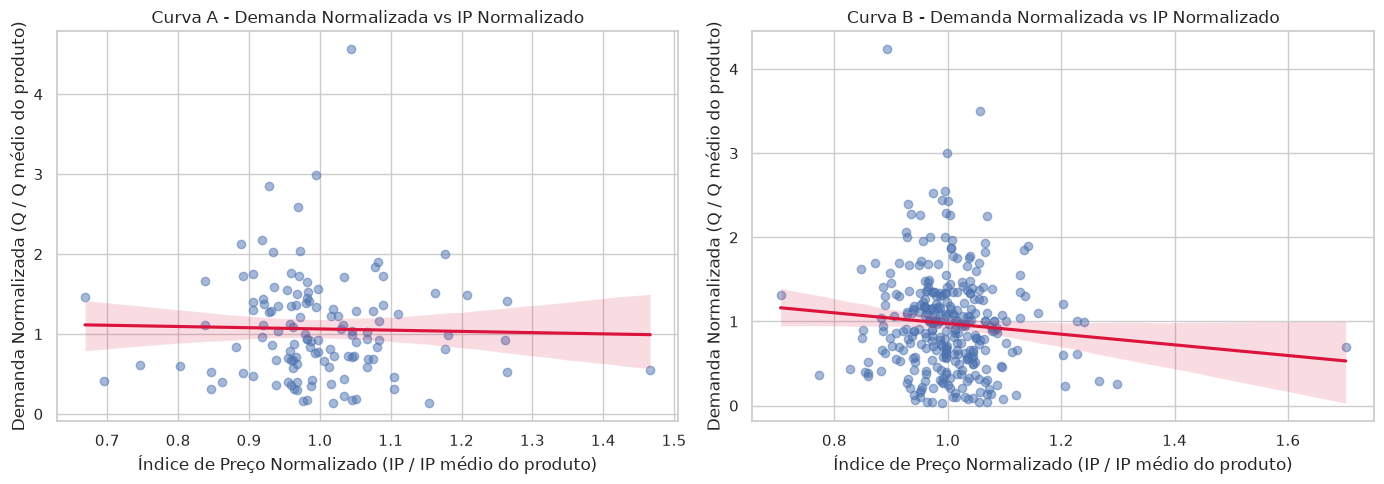

In [6]:
# Visualização da regressão por Curva
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for idx, c in enumerate(['A', 'B']):
    sub_p = df_norm[df_norm['curva'] == c]
    sns.regplot(
        data=sub_p, x='ip_norm', y='qtd_norm', ax=axes[idx],
        scatter_kws={'alpha': 0.5}, line_kws={'color': 'crimson'}
    )
    axes[idx].set_title(f'Curva {c} - Demanda Normalizada vs IP Normalizado')
    axes[idx].set_xlabel('Índice de Preço Normalizado (IP / IP médio do produto)')
    axes[idx].set_ylabel('Demanda Normalizada (Q / Q médio do produto)')

plt.tight_layout()
plt.show()

### 5. Estimativa por Categoria

Utilizamos diretamente a coluna `categoria` já tratada no pré-processamento (que manteve as 32 categorias com mais de 5 linhas no painel de treino e agrupou as demais em `"Outras"`).

In [7]:
elast_categoria = (
    df_norm.groupby('categoria')
    .apply(lambda g: calcular_elasticidade(g, col_ip='ip_norm', col_q='qtd_norm'), include_groups=False)
    .reset_index()
    .sort_values(by='r2_log', ascending=False)
)

print("=== ELASTICIDADE POR CATEGORIA (TOP 15 POR R²) ===")
display(elast_categoria.head(15))

# Comparação de R² médio entre os diferentes níveis de agregação
resumo_niveis = pd.DataFrame({
    'Nível de Agregação': ['Por Produto', 'Por Categoria (Normalizado)', 'Por Curva (Painel Normalizado)', 'Por Curva (Agregado Semanal)'],
    'R² Médio (Log-Log)': [
        elast_produto['r2_log'].mean(),
        elast_categoria['r2_log'].mean(),
        elast_curva_painel['r2_log'].mean(),
        elast_curva_agregada['r2_log'].mean()
    ],
    'Proporção de Grupos Válidos (%)': [
        elast_produto['elasticidade_log'].notna().mean() * 100,
        elast_categoria['elasticidade_log'].notna().mean() * 100,
        elast_curva_painel['elasticidade_log'].notna().mean() * 100,
        elast_curva_agregada['elasticidade_log'].notna().mean() * 100
    ]
})
display(resumo_niveis)

=== ELASTICIDADE POR CATEGORIA (TOP 15 POR R²) ===


,categoria,n_obs,ip_medio,qtd_media,elasticidade_linear,r2_linear,elasticidade_log,r2_log,p_valor_log
25,Categoria 41,3.0000,1.0000,1.0000,1.5283,0.8280,1.6005,0.8972,0.2078
12,Categoria 25,5.0000,1.0000,1.0000,3.5836,0.6510,4.3197,0.7665,0.0517
31,Outras,10.0000,1.0000,1.0000,5.9791,0.8444,6.1744,0.6600,0.0043
30,Categoria 9,24.0000,1.0000,1.0000,-7.3168,0.3081,-8.7867,0.3191,0.0040
29,Categoria 8,16.0000,1.0000,1.0000,-3.1665,0.2640,-4.4291,0.2139,0.0713
27,Categoria 46,7.0000,1.0000,1.0000,3.5990,0.3190,4.0411,0.1989,0.3159
14,Categoria 27,6.0000,1.0000,1.0000,2.6640,0.1934,2.6637,0.1945,0.3814
13,Categoria 26,8.0000,1.0000,1.0000,-4.8698,0.1644,-4.6230,0.1456,0.3510
11,Categoria 24,4.0000,1.0000,1.0000,1.3052,0.0794,1.6423,0.1223,0.6503
16,Categoria 3,7.0000,1.0000,1.0000,-1.6847,0.0395,-3.6488,0.1173,0.4520


,Nível de Agregação,R² Médio (Log-Log),Proporção de Grupos Válidos (%)
0,Por Produto,0.2101,74.7253
1,Por Categoria (Normalizado),0.1370,100.0000
2,Por Curva (Painel Normalizado),0.0041,100.0000
3,Por Curva (Agregado Semanal),0.0260,100.0000


### 6. Exportação das Features de Elasticidade para o Modelo de Demanda

Exportamos as tabelas de elasticidade em `../data/processed/` com as chaves exatas (`curva` e `categoria`) usadas nos arquivos `treino_processado.csv`, `validacao_processado.csv` e `teste_processado.csv`.

In [8]:
os.makedirs('../data/processed', exist_ok=True)

# 1. Tabela de elasticidade por Curva
df_export_curva = elast_curva_painel[['curva', 'elasticidade_log', 'r2_log']].rename(columns={
    'elasticidade_log': 'elasticidade_curva',
    'r2_log': 'r2_elasticidade_curva'
})

sem_cadastro_curva = pd.DataFrame({
    'curva': ['Sem cadastro'],
    'elasticidade_curva': [0.0],
    'r2_elasticidade_curva': [0.0]
})
df_export_curva = pd.concat([df_export_curva, sem_cadastro_curva], ignore_index=True)
df_export_curva.to_csv('../data/processed/elasticidade_curva.csv', index=False)

# 2. Tabela de elasticidade por Categoria (garantindo cobertura de todas as 32 categorias + 'Outras' + 'Sem cadastro')
todas_categorias = pd.DataFrame({'categoria': df_treino['categoria'].unique()})
df_export_cat = todas_categorias.merge(
    elast_categoria[['categoria', 'elasticidade_log', 'r2_log']],
    on='categoria',
    how='left'
).rename(columns={
    'elasticidade_log': 'elasticidade_categoria',
    'r2_log': 'r2_elasticidade_categoria'
})

# Para 'Sem cadastro', define 0.0; para categorias cadastradas sem variância de IP no treino, imputa a média das categorias
media_elast_cat = df_export_cat.loc[df_export_cat['categoria'] != 'Sem cadastro', 'elasticidade_categoria'].mean()
df_export_cat.loc[df_export_cat['categoria'] == 'Sem cadastro', ['elasticidade_categoria', 'r2_elasticidade_categoria']] = 0.0
df_export_cat['elasticidade_categoria'] = df_export_cat['elasticidade_categoria'].fillna(media_elast_cat)
df_export_cat['r2_elasticidade_categoria'] = df_export_cat['r2_elasticidade_categoria'].fillna(0.0)

df_export_cat.to_csv('../data/processed/elasticidade_categoria.csv', index=False)

print("Arquivos exportados com sucesso em ../data/processed/:")
display(df_export_curva)
display(df_export_cat.head(10))

Arquivos exportados com sucesso em ../data/processed/:


,curva,elasticidade_curva,r2_elasticidade_curva
0,A,-0.1572,0.0006
1,B,-0.8829,0.0075
2,Sem cadastro,0.0000,0.0000


,categoria,elasticidade_categoria,r2_elasticidade_categoria
0,Categoria 27,2.6637,0.1945
1,Sem cadastro,0.0000,0.0000
2,Categoria 39,-0.0698,0.0000
3,Categoria 1,-3.5060,0.0756
4,Categoria 7,-1.0130,0.0526
5,Categoria 32,0.4710,0.0000
6,Categoria 19,2.2158,0.0950
7,Categoria 36,0.0488,0.0000
8,Categoria 8,-4.4291,0.2139
9,Categoria 20,-1.1192,0.0167
